In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import os
import geopandas as gpd
import contextily as ctx

In [2]:
pypsa_data_dir = "../Data/eq_handoff_fullcats"
scenario = "aggressive"
agg_type = "disagg"
asset_fp = os.path.join(pypsa_data_dir, scenario, agg_type, "assets_all.csv")
asset_df = pd.read_csv(asset_fp)
asset_gdf = gpd.GeoDataFrame(asset_df, geometry=gpd.points_from_xy(asset_df.lon, asset_df.lat))

In [3]:
asset_gdf.groupby(['asset_type', 'carrier']).size()

asset_type    carrier            
generator     CATS                   2149
              CCGT                     17
              CCGT-95CCS               16
              OCGT                     24
              biomass                  17
              coal                     14
              geothermal                5
              hydro                    20
              hydrogen_ct              13
              nuclear                  21
              oil                      13
              onwind                  355
              solar                   354
              waste                     2
storage_unit  4hr_battery_storage      57
              8hr_battery_storage     198
              battery                  15
dtype: int64

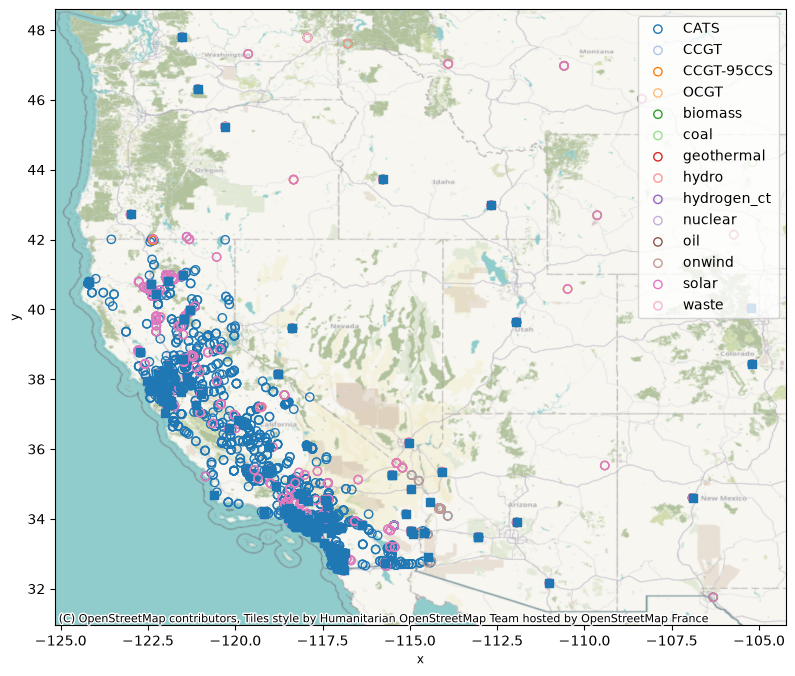

In [4]:
fig, ax = plt.subplots(figsize=(10, 8))
asset_gdf[asset_gdf['asset_type'] == 'generator'].plot(ax=ax,
    marker='o', facecolor='none', column = 'carrier', legend=True,
    legend_kwds={'loc': 'upper right'})
asset_gdf[asset_gdf['asset_type'] == 'storage_unit'].plot(ax=ax,
    marker='s', label='storage_unit', legend=True)
ctx.add_basemap(ax, crs='EPSG:4326')

/resnick/groups/enceladus/jyzhao/CAPowerResilience/.venv/lib/python3.11/site-packages/geopandas/plotting.py:475: UserWarning: You passed both c and facecolor/facecolors for the markers. c has precedence over facecolor/facecolors. This behavior may change in the future.
  collection = ax.scatter(


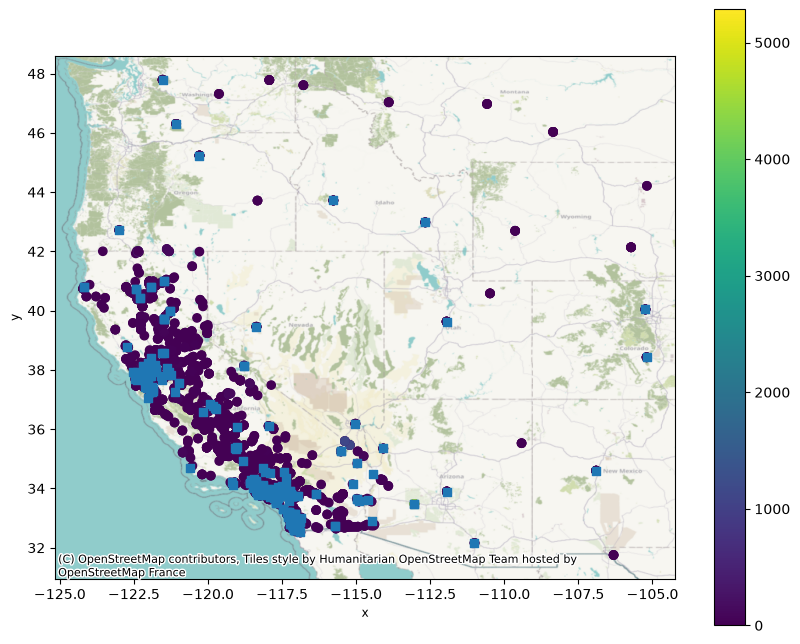

In [5]:
fig, ax = plt.subplots(figsize=(10, 8))
asset_gdf[asset_gdf['asset_type'] == 'generator'].plot(ax=ax,
    marker='o', facecolor='none', column = 'new_mw', legend=True,
    )
asset_gdf[asset_gdf['asset_type'] == 'storage_unit'].plot(ax=ax,
    marker='s', label='storage_unit', legend=True)
ctx.add_basemap(ax, crs='EPSG:4326')